<a href="https://colab.research.google.com/github/Maryam-Yaqoob/Hunarmand-Punjab-Machine-Learning-and-Data-Science/blob/main/House_Price_Prediction_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Advanced House Price Prediction with Feature Engineering and Regression Analysis

**Dataset:** the notebook downloads the Kaggle *Housing Prices Dataset* (`yasserh/housing-prices-dataset`) with `kagglehub`. If the download fails it looks for a local `Housing.csv`, and finally falls back to a synthetic dataset so it always runs.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings; warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

---
## A. Data Analysis and Statistical Investigation

### A1. Load the dataset using Pandas

In [2]:
KAGGLE_DATASET = "yasserh/housing-prices-dataset"   # Kaggle "Housing Prices Dataset"
LOCAL_CSV = "Housing.csv"                            # used if Kaggle download fails
TARGET = "price"

def make_synthetic(n=1000, seed=42):
    rng = np.random.default_rng(seed)
    area = rng.normal(1800, 500, n).clip(500, 5000)
    bedrooms = rng.integers(1, 6, n)
    bathrooms = np.clip(bedrooms - rng.integers(0, 2, n), 1, 5)
    age = rng.integers(0, 50, n)
    location = rng.choice(["Downtown", "Suburb", "Rural"], n, p=[0.3, 0.5, 0.2])
    loc_eff = pd.Series(location).map({"Downtown": 90000, "Suburb": 40000, "Rural": 0}).values
    price = (50*area + 15000*bedrooms + 20000*bathrooms - 800*age + loc_eff
             + rng.normal(0, 25000, n))
    df = pd.DataFrame(dict(area=area.round(0), bedrooms=bedrooms, bathrooms=bathrooms,
                           age=age, location=location, price=price.round(0)))
    # inject missing values and a few outliers
    for c in ["area", "age", "bathrooms"]:
        df.loc[rng.choice(n, 30, replace=False), c] = np.nan
    df.loc[rng.choice(n, 5, replace=False), "price"] *= 4
    return df

def load_data():
    """1) Kaggle download  2) local CSV  3) synthetic fallback"""
    try:
        import subprocess, sys, glob
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=False)
        import kagglehub
        folder = kagglehub.dataset_download(KAGGLE_DATASET)
        csv_file = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)[0]
        print("Downloaded from Kaggle:", csv_file)
        return pd.read_csv(csv_file)
    except Exception as e:
        print("Kaggle download failed:", repr(e)[:150])
    if os.path.exists(LOCAL_CSV):
        print("Using local file:", LOCAL_CSV)
        return pd.read_csv(LOCAL_CSV)
    print("Using synthetic dataset (for demo only)")
    return make_synthetic()

df = load_data()
df.head()

Using Colab cache for faster access to the 'housing-prices-dataset' dataset.
Downloaded from Kaggle: /kaggle/input/housing-prices-dataset/Housing.csv


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


### A2. Shape, data types and descriptive statistics

In [3]:
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
df.describe(include="all").T

Shape: (545, 13)

Data types:
 price                int64
area                 int64
bedrooms             int64
bathrooms            int64
stories              int64
mainroad            object
guestroom           object
basement            object
hotwaterheating     object
airconditioning     object
parking              int64
prefarea            object
furnishingstatus    object
dtype: object


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
price,545.0,NaN,NaN,NaN,4766729.247706,1870439.615657,1750000.0,3430000.0,4340000.0,5740000.0,13300000.0
area,545.0,NaN,NaN,NaN,5150.541284,2170.141023,1650.0,3600.0,4600.0,6360.0,16200.0
bedrooms,545.0,NaN,NaN,NaN,2.965138,0.738064,1.0,2.0,3.0,3.0,6.0
bathrooms,545.0,NaN,NaN,NaN,1.286239,0.50247,1.0,1.0,1.0,2.0,4.0
stories,545.0,NaN,NaN,NaN,1.805505,0.867492,1.0,1.0,2.0,2.0,4.0
mainroad,545,2,yes,468,NaN,NaN,NaN,NaN,NaN,NaN,NaN
guestroom,545,2,no,448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
basement,545,2,no,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hotwaterheating,545,2,no,520,NaN,NaN,NaN,NaN,NaN,NaN,NaN
airconditioning,545,2,no,373,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### A3. Missing values and outliers (IQR method)

Missing values per column:
 None

Outliers per numeric column (IQR rule):
price        15
area         12
bedrooms     12
bathrooms     1
stories      41
parking      12
dtype: int64


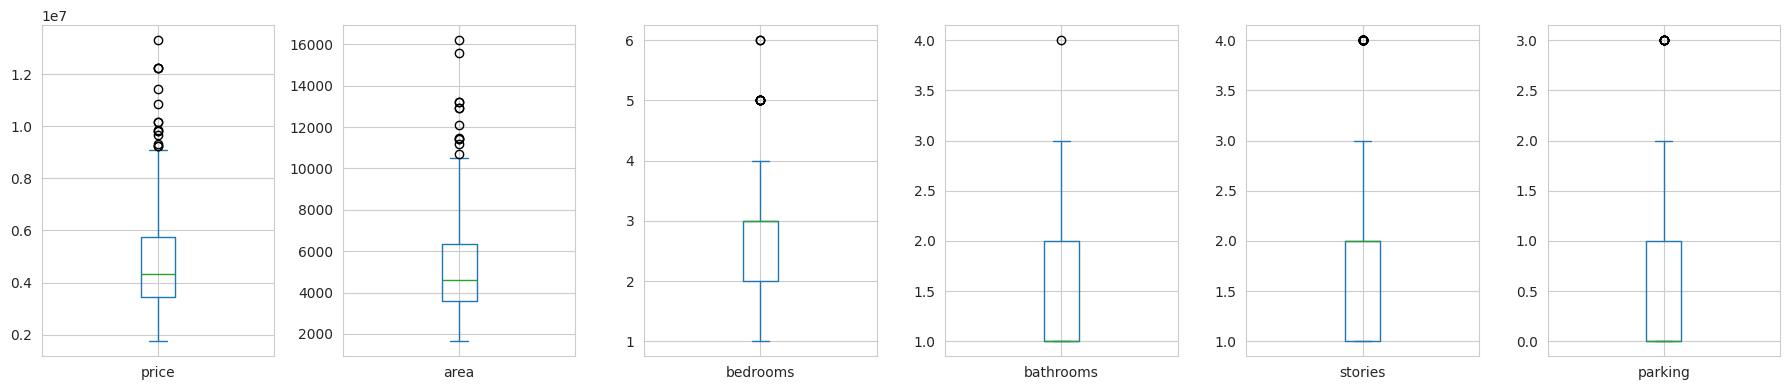

In [4]:
missing = df.isnull().sum()
print("Missing values per column:\n", missing[missing > 0] if missing.sum() else "None")

num_cols = df.select_dtypes(include=np.number).columns
outliers = {}
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    mask = (df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)
    outliers[c] = int(mask.sum())
print("\nOutliers per numeric column (IQR rule):")
print(pd.Series(outliers))

df[num_cols].plot(kind="box", subplots=True, layout=(1, len(num_cols)), figsize=(3*len(num_cols), 4))
plt.tight_layout(); plt.show()

### A4. Mean, median, standard deviation and correlation with price

,mean,median,std
price,4.766729e+06,4340000.0,1.870440e+06
area,5.150541e+03,4600.0,2.170141e+03
bedrooms,2.965138e+00,3.0,7.380639e-01
bathrooms,1.286239e+00,1.0,5.024696e-01
stories,1.805505e+00,2.0,8.674925e-01
parking,6.935780e-01,0.0,8.615858e-01


Correlation with price
price        1.000000
area         0.535997
bathrooms    0.517545
stories      0.420712
parking      0.384394
bedrooms     0.366494
Name: price, dtype: float64


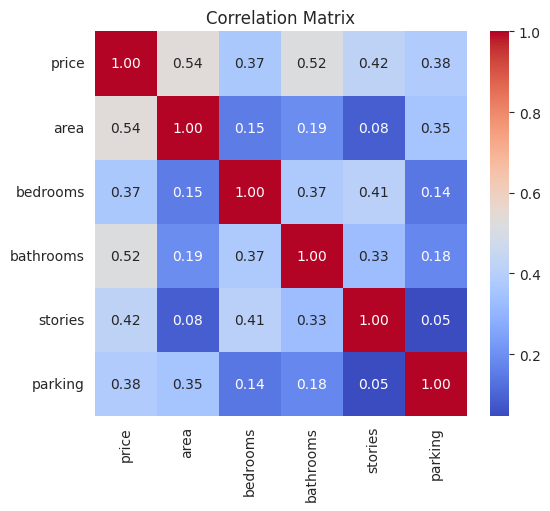

In [5]:
stats = df[num_cols].agg(["mean", "median", "std"]).T
display(stats)

corr = df[num_cols].corr()
print("Correlation with", TARGET)
print(corr[TARGET].sort_values(ascending=False))
plt.figure(figsize=(6, 5)); sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f"); plt.title("Correlation Matrix"); plt.show()

---
## B. Data Preprocessing and Feature Engineering

### B1–B2. Feature selection
Features are chosen using correlation with price (|r| above a small threshold) plus categorical columns. At least three features are selected.

In [6]:
target_corr = corr[TARGET].drop(TARGET).abs().sort_values(ascending=False)
selected_num = target_corr[target_corr > 0.1].index.tolist()
if len(selected_num) < 3:
    selected_num = target_corr.index[:3].tolist()
cat_cols = df.select_dtypes(exclude=np.number).columns.tolist()
print("Selected numeric features:", selected_num)
print("Categorical features:", cat_cols)

data = df[selected_num + cat_cols + [TARGET]].copy()
data = data.dropna(subset=[TARGET])        # rows without a target cannot be used

Selected numeric features: ['area', 'bathrooms', 'stories', 'parking', 'bedrooms']
Categorical features: ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


### B3. Encode categorical variables (one-hot encoding)

In [7]:
data = pd.get_dummies(data, columns=cat_cols, drop_first=True, dtype=int)
data.head()

,area,bathrooms,stories,parking,bedrooms,price,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,7420,2,3,2,4,13300000,1,0,0,0,1,1,0,0
1,8960,4,4,3,4,12250000,1,0,0,0,1,0,0,0
2,9960,2,2,2,3,12250000,1,0,1,0,0,1,1,0
3,7500,2,2,3,4,12215000,1,0,1,0,1,1,0,0
4,7420,1,2,2,4,11410000,1,1,1,0,1,0,0,0


### B5 (first part). Separate X / y and 80:20 train-test split
The split is done **before** imputation and scaling so that test-set statistics never leak into training.

In [8]:
X = data.drop(columns=[TARGET])
y = data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (436, 13)  Test: (109, 13)


### B1. Handle missing values (median imputation, fitted on training data only)

In [9]:
train_medians = X_train.median()
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)       # use TRAIN medians
print("Missing after imputation:", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

Missing after imputation: 0 0


### B4. Feature scaling (StandardScaler fitted on training data only)

In [10]:
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)
X_train_s.describe().loc[["mean", "std"]].round(3)

,area,bathrooms,stories,parking,bedrooms,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
mean,0.000,0.000,0.000,-0.000,0.000,0.000,0.000,-0.000,-0.000,0.000,-0.000,-0.000,-0.000
std,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001


---
## C. Regression Model Development

### C1–C2. Implement and train Linear Regression

In [11]:
model = LinearRegression()
model.fit(X_train_s, y_train)
print("Model trained.")

Model trained.


### C3. Predictions on test data

In [12]:
y_pred = model.predict(X_test_s)
pd.DataFrame({"Actual": y_test.values[:5], "Predicted": y_pred[:5].round(0)})

,Actual,Predicted
0,4060000,5164654.0
1,6650000,7224722.0
2,3710000,3109863.0
3,6440000,4612075.0
4,2800000,3294646.0


### C4. Coefficients and intercept

In [13]:
print("Intercept:", round(model.intercept_, 2))
coef_df = pd.DataFrame({"Feature": X.columns, "Coefficient": model.coef_}).sort_values("Coefficient", key=abs, ascending=False)
coef_df

Intercept: 4706527.39


,Feature,Coefficient
1,bathrooms,521879.027748
0,area,519552.416340
9,airconditioning_yes,365157.393851
2,stories,349251.438906
10,prefarea_yes,266656.351993
12,furnishingstatus_unfurnished,-192015.917982
3,parking,192005.953667
7,basement_yes,187067.803214
8,hotwaterheating_yes,149862.702991
5,mainroad_yes,128498.628215


### C5. Predict the price of a new house (manually supplied values)
Edit the values below to match your dataset's features.

In [14]:
# Start from typical (median) values of the training data, then override with your own values
new_house = X_train.median().to_dict()
# --- edit these values to describe the house you want to price ---
custom = {"area": 5000, "bedrooms": 3, "bathrooms": 2, "stories": 2, "parking": 1,
          "airconditioning_yes": 1, "prefarea_yes": 1,            # Housing.csv dummies
          "location_Suburb": 1}                                   # synthetic-data dummy
for k, v in custom.items():
    if k in new_house: new_house[k] = v
new_df = pd.DataFrame([new_house])[X.columns]
print("Input house:\n", new_df.iloc[0].to_dict())

new_scaled = scaler.transform(new_df)    # same scaler as training
print(f"\nPredicted price: {model.predict(new_scaled)[0]:,.2f}")

Input house:
 {'area': 5000.0, 'bathrooms': 2.0, 'stories': 2.0, 'parking': 1.0, 'bedrooms': 3.0, 'mainroad_yes': 1.0, 'guestroom_yes': 0.0, 'basement_yes': 0.0, 'hotwaterheating_yes': 0.0, 'airconditioning_yes': 1.0, 'prefarea_yes': 1.0, 'furnishingstatus_semi-furnished': 0.0, 'furnishingstatus_unfurnished': 0.0}

Predicted price: 6,688,134.41


---
## D. Model Evaluation

In [15]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print(f"MAE : {mae:,.2f}")
print(f"MSE : {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R2  : {r2:.4f}")

MAE : 970,043.40
MSE : 1,754,318,687,330.67
RMSE: 1,324,506.96
R2  : 0.6529


---
## E. Visualization and Analysis

### E1. Actual vs predicted prices

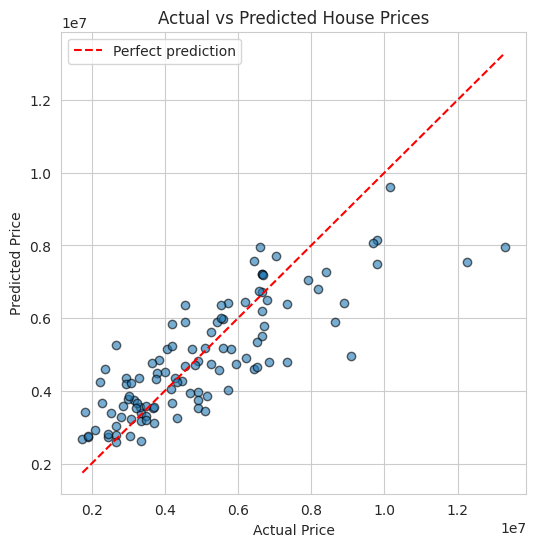

In [16]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6, edgecolor="k")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual Price"); plt.ylabel("Predicted Price"); plt.title("Actual vs Predicted House Prices")
plt.legend(); plt.show()

### E2. Histogram of house prices

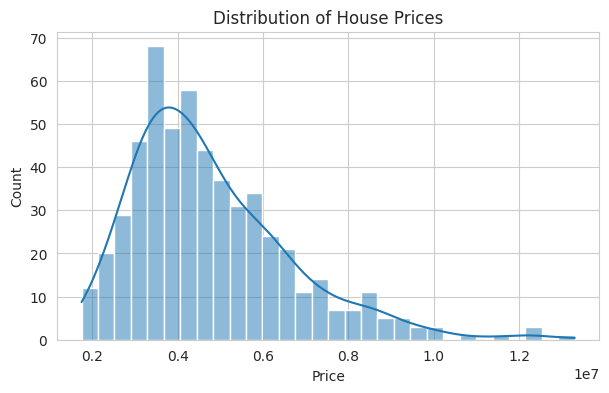

In [17]:
plt.figure(figsize=(7, 4))
sns.histplot(df[TARGET].dropna(), bins=30, kde=True)
plt.xlabel("Price"); plt.title("Distribution of House Prices"); plt.show()

### E3. Relationship between an important feature and price

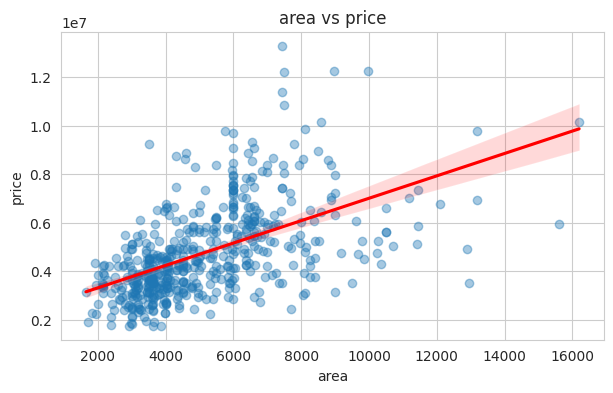

In [18]:
top_feature = selected_num[0]      # most correlated feature
plt.figure(figsize=(7, 4))
sns.regplot(x=df[top_feature], y=df[TARGET], scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
plt.title(f"{top_feature} vs {TARGET}"); plt.show()

### E4. Prediction errors for at least 10 test samples

In [19]:
errors = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred})
errors["Error"] = errors["Actual"] - errors["Predicted"]
errors["Abs Error"] = errors["Error"].abs()
errors["% Error"] = (errors["Abs Error"] / errors["Actual"] * 100).round(2)
errors.head(10).round(2)

,Actual,Predicted,Error,Abs Error,% Error
0,4060000,5164653.90,-1104653.90,1104653.90,27.21
1,6650000,7224722.30,-574722.30,574722.30,8.64
2,3710000,3109863.24,600136.76,600136.76,16.18
3,6440000,4612075.33,1827924.67,1827924.67,28.38
4,2800000,3294646.26,-494646.26,494646.26,17.67
5,4900000,3532275.10,1367724.90,1367724.90,27.91
6,5250000,5611774.57,-361774.57,361774.57,6.89
7,4543000,6368145.99,-1825145.99,1825145.99,40.17
8,2450000,2722856.96,-272856.96,272856.96,11.14
9,3353000,2629405.62,723594.38,723594.38,21.58
